# (1) Example_MNIST_CNN_Train

Questo notebook contiene un esempio su come definire una Convolutional Neural Network (CNN) ed allenarla per eseguire Image Recognition sul dataset MNIST. La rete viene salvata alla fine del training.

## 1. Setup and Imports

Importiamo le librarie che ci serviranno

In [1]:
# Importazione delle librerie fondamentali per il progetto:
# numpy e matplotlib per array matematici e generazione grafici.

import copy
import numpy as np
import matplotlib.pyplot as plt

# torch e torchvision per la costruzione, gestione e trasformazione della rete neurale.
import torch
from torchvision import datasets, transforms

# tqdm per la generazione delle barre di avanzamento durante l'esecuzione.
from tqdm import tqdm

## 2. Data Preparation

Scarica il dataset MNIST per allenare la rete

In [2]:
# ---------------------------------------------------------------------------
# RIPRODUCIBILITÀ: fissiamo i generatori casuali, così a parità di codice
# otteniamo (quasi) gli stessi risultati ad ogni esecuzione. Utile per la tesi.
# ---------------------------------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Numero di campioni (immagini) elaborati in parallelo in una singola iterazione.
batch_size = 64

# MIGLIORAMENTO 1 - DATA AUGMENTATION (solo sul training set).
# Durante il training ogni immagine viene leggermente ruotata, traslata e scalata in modo casuale:
# la rete vede ogni epoca versioni "nuove" delle stesse cifre e generalizza meglio.
# Mettere False per tornare al comportamento originale (utile per il confronto nella tesi).
USE_AUGMENTATION = True

normalize = transforms.Normalize((0.1307,), (0.3081,))

# Trasformazione delle etichette (identica all'originale): intero -> vettore one-hot di 10 elementi.
target_tf = transforms.Compose([
    lambda x:torch.tensor([x]),
    lambda x:torch.nn.functional.one_hot(x,10).float(),
    lambda x:x.squeeze(),
    ])

# Pre-elaborazione per il TRAINING (con eventuale augmentation, applicata PRIMA di ToTensor)
if USE_AUGMENTATION:
    train_tf = transforms.Compose([
        transforms.RandomAffine(degrees=8, translate=(0.08, 0.08), scale=(0.92, 1.08)),
        transforms.ToTensor(),
        normalize,
        ])
else:
    train_tf = transforms.Compose([transforms.ToTensor(), normalize])

# Pre-elaborazione per VALIDAZIONE e TEST: nessuna augmentation, solo conversione e normalizzazione.
eval_tf = transforms.Compose([transforms.ToTensor(), normalize])

# Le 60.000 immagini di training vengono caricate DUE volte: una versione con augmentation (per allenare)
# e una "pulita" (per validare). In questo modo la validazione non viene falsata dall'augmentation.
mnist_data_train = datasets.MNIST("./", download=True, train=True, transform=train_tf, target_transform=target_tf)
mnist_data_val   = datasets.MNIST("./", download=True, train=True, transform=eval_tf,  target_transform=target_tf)

# Il test set (10.000 immagini) resta intoccato fino alla valutazione finale.
mnist_test = datasets.MNIST("./", download=True, train=False, transform=eval_tf, target_transform=target_tf)

# Split 80% training / 20% validazione, con gli STESSI indici per le due versioni del dataset.
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(mnist_data_train), generator=g).tolist()
n_train = int(0.8 * len(perm))
ds_train = torch.utils.data.Subset(mnist_data_train, perm[:n_train])
ds_val   = torch.utils.data.Subset(mnist_data_val,   perm[n_train:])

# DataLoader: 'shuffle=True' rimescola le immagini ad ogni epoca.
mnist_loader_train = torch.utils.data.DataLoader(ds_train, batch_size=batch_size, shuffle=True)
mnist_loader_val = torch.utils.data.DataLoader(ds_val, batch_size=batch_size, shuffle=False)

# Create test set loader
mnist_loader_test = torch.utils.data.DataLoader(mnist_test, batch_size=batch_size, shuffle=False)
N_test = len(mnist_loader_test.dataset)

## 3. Define the CNN Model

Definisci la tua rete neurale

In [3]:
# Definizione dell'architettura (topologia) della Rete Neurale Convoluzionale (CNN).
# Struttura ibrida composta da strati convoluzionali (Conv2d) per l'estrazione delle feature spaziali 
# e strati completamente connessi (Linear) per la classificazione probabilistica (output su 10 classi, da 0 a 9).

# Define the CNN topology
def mnist_cnn():
    # Inizializza un contenitore sequenziale: i dati attraverseranno i nodi esattamente nell'ordine elencato.
    return torch.nn.Sequential(
        # Primo strato convoluzionale (filtro spaziale): riceve 1 canale di input (immagine in scala di grigi),
        # genera 8 canali di output (feature maps), usando una finestra mobile (kernel) 3x3. 'stride=2' dimezza la risoluzione spaziale.
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),

        # Funzione di attivazione non lineare (Rectified Linear Unit). Azzera i segnali negativi e lascia inalterati i positivi.
        torch.nn.ReLU(),

        # Secondo strato convoluzionale: prende le 8 feature maps in ingresso ed estrae 16 nuovi canali, sempre dimezzando la risoluzione spaziale.
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),

        # Srotola le matrici multidimensionali risultanti in un singolo vettore monodimensionale, preparandole per il perceptrone classico.
        torch.nn.Flatten(),

        # Strato completamente connesso (moltiplicazione matriciale pura): mappa i 576 nodi in input su 16 neuroni nascosti.
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),

        # Strato di output finale: riduce i 16 neuroni nascosti ai 10 nodi di uscita, che corrispondono alle 10 cifre possibili (da 0 a 9).
        torch.nn.Linear(16, 10)
        )

# Definizione Rete con Dropout
def mnist_cnn_dropout():
    return torch.nn.Sequential(
        torch.nn.Conv2d(1, 8, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Conv2d(8, 16, 3, padding='valid', stride=2),
        torch.nn.ReLU(),
        torch.nn.Flatten(),
        torch.nn.Dropout(p=0.3), # Spegne il 30% dei neuroni
        torch.nn.Linear(576, 16),
        torch.nn.ReLU(),
        torch.nn.Linear(16, 10)
    )

## 4. Training and Testing Functions

Definisci una funzione Wrapper che esponga un'interfaccia per lanciare training e testing sul modello.
Questa procedura non é "standard" Pythorch ma facilita l'utilizzo successivo del framework Cross-Sim per modellare l'implementazione via In-Memory Computing.

Per il training viene utilizzato l'ottimizzatore AdamW (Adam con *weight decay*) con learning rate iniziale $10^{-3}$, ridotto gradualmente a zero da uno scheduler *cosine annealing*.
Al termine, viene ripristinato il modello dell'epoca con la validation loss più bassa.

In [4]:
# Creazione di una classe "Wrapper" personalizzata per la gestione del ciclo di vita della rete.
# Questa astrazione architetturale è propedeutica per la successiva integrazione con il framework Cross-Sim per l'In-Memory Computing.

# Wrapper for training the CNN
class SequentialWrapper():
    def __init__(self, net, loss, learning_rate=1e-3, weight_decay=1e-2, use_scheduler=True):
        self.net = net
        self.loss = loss
        self.learning_rate = learning_rate
        self.use_scheduler = use_scheduler
        self.best_epoch = None

        # MIGLIORAMENTO 2 - AdamW: come Adam, ma applica il weight decay (penalizza i pesi grandi)
        # nel modo corretto. Può contribuire a ridurre l'overfitting e a tenere i pesi più "piccoli"
        # (effetto da verificare sperimentalmente: con questa rete l'overfitting è comunque praticamente nullo).
        self.optimizer = torch.optim.AdamW(self.net.parameters(), lr=self.learning_rate, weight_decay=weight_decay)
        self.scheduler = None

    # Definisce le funzioni di forward, calcolo dell'errore (CrossEntropyLoss) e ottimizzazione.
    def forward(self, x):
        return self.net(x)
    
    def training_step(self, batch):
        self.optimizer.zero_grad()
        pred = self.forward(batch[0])
        loss = self.loss(pred, batch[1])
        loss.backward()
        self.optimizer.step()
        return loss

    def validation_step(self, batch):
        # In validazione non servono i gradienti: si risparmia memoria e tempo.
        with torch.no_grad():
            pred = self.forward(batch[0])
            loss = self.loss(pred, batch[1])
        return loss
    
    def train_epoch(self, train_loader, val_loader):
        loss_train, loss_val = 0, 0

        # CORREZIONE - modalità TRAIN: il Dropout è ATTIVO durante l'addestramento.
        self.net.train()
        for minibatch in iter(train_loader):
            loss_train += self.training_step(minibatch).detach()

        # CORREZIONE - modalità EVAL: il Dropout è SPENTO durante la validazione.
        # Nella versione originale la validazione veniva fatta col Dropout acceso, quindi la
        # validation loss della rete con Dropout risultava artificialmente più alta.
        self.net.eval()
        for minibatch in iter(val_loader):
            loss_val += self.validation_step(minibatch).detach()

        return loss_train/len(train_loader), loss_val/len(val_loader)
    
    def train(self, train_loader, val_loader, epochs):
        loss_train, loss_val = np.zeros(epochs), np.zeros(epochs)

        # MIGLIORAMENTO 3 - Scheduler: il learning rate parte da 1e-3 e scende dolcemente verso 0.
        # Passi grandi all'inizio per imparare in fretta, passi piccoli alla fine per rifinire.
        if self.use_scheduler:
            self.scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(self.optimizer, T_max=epochs)

        # MIGLIORAMENTO 4 - Checkpoint: teniamo da parte i pesi dell'epoca con la validation loss minore.
        best_val, best_state = float('inf'), None

        for e in tqdm(range(0, epochs)):
            lt, lv = self.train_epoch(train_loader, val_loader)
            loss_train[e] = float(lt)
            loss_val[e] = float(lv)

            if self.scheduler is not None:
                self.scheduler.step()

            if loss_val[e] < best_val:
                best_val = loss_val[e]
                self.best_epoch = e + 1
                best_state = copy.deepcopy(self.net.state_dict())

        # Ripristina il modello migliore e lascia la rete in modalità eval (pronta per l'inferenza).
        if best_state is not None:
            self.net.load_state_dict(best_state)
        self.net.eval()
        return loss_train, loss_val

# Questa astrazione architetturale è propedeutica per la successiva integrazione con il framework Cross-Sim per l'In-Memory Computing.

# Create the wrapped PyTorch of the CNN model
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())

## 5. PyTorch Training

Allena (_training_) la rete per il numero di _epoche_ indicato.


In [5]:
# Esecuzione del ciclo di addestramento (Training) per un numero definito di epoche (N_epochs = 30).

# Number of training epochs
N_epochs = 30

# Prepariamo i due "cervelli" (stessa ricetta di training per entrambi, così il confronto è equo)
torch.manual_seed(SEED)
mnist_cnn_pt = SequentialWrapper(mnist_cnn(), torch.nn.CrossEntropyLoss())
torch.manual_seed(SEED)
mnist_cnn_drop = SequentialWrapper(mnist_cnn_dropout(), torch.nn.CrossEntropyLoss())

print("--- INIZIO ADDESTRAMENTO RETE STANDARD ---")
loss_train_pt, loss_val_pt = mnist_cnn_pt.train(mnist_loader_train, mnist_loader_val, N_epochs)

print("\n--- INIZIO ADDESTRAMENTO RETE CON DROPOUT ---")
loss_train_drop, loss_val_drop = mnist_cnn_drop.train(mnist_loader_train, mnist_loader_val, N_epochs)

print("\nEpoca migliore (validation loss minima) - Standard: {}, Dropout: {}".format(
    mnist_cnn_pt.best_epoch, mnist_cnn_drop.best_epoch))

--- INIZIO ADDESTRAMENTO RETE STANDARD ---


100%|██████████| 30/30 [05:37<00:00, 11.24s/it]



--- INIZIO ADDESTRAMENTO RETE CON DROPOUT ---


100%|██████████| 30/30 [05:16<00:00, 10.56s/it]


Epoca migliore (validation loss minima) - Standard: 26, Dropout: 30


Rappresenta le curve di apprendimento (_loss_) per il subset di _training_ e di _validation_.

**Attenzione:** le due curve non sono misurate nelle stesse condizioni. La training loss è la media calcolata durante l'epoca, con dropout acceso e immagini con augmentation; la validation loss è calcolata a fine epoca, con dropout spento e immagini pulite. Per questo la validation può risultare più bassa della training senza che ci sia un errore. Per valutare l'overfitting reale si usa la tabella train / validation / test della sezione 7.

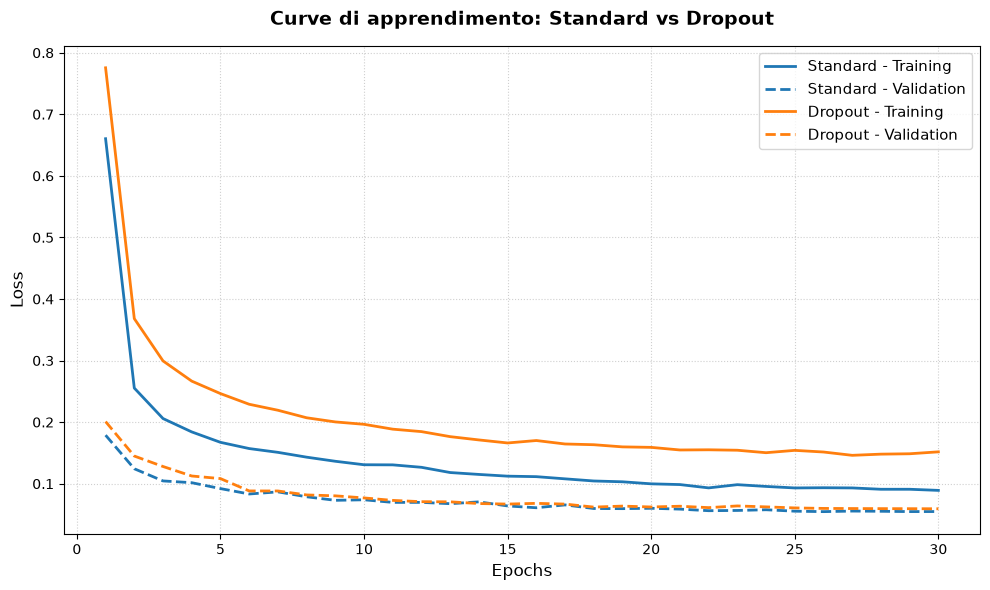

In [6]:
# Visualizzazione grafica delle curve di Training Loss e Validation Loss (curve di apprendimento).
# Utile per vedere se l'addestramento converge. NON è una misura diretta dell'overfitting: training e validation
# loss sono calcolate in condizioni diverse (vedi sezione 7 per il confronto equo train / validation / test).

x_axis_epochs = np.arange(1, N_epochs + 1)

plt.figure(figsize=(10, 6))

# Traccia la Rete Standard (Blu)
plt.plot(x_axis_epochs, loss_train_pt, label='Standard - Training', color='#1f77b4', linewidth=2)
plt.plot(x_axis_epochs, loss_val_pt, label='Standard - Validation', color='#1f77b4', linewidth=2, linestyle='--')

# Traccia la Rete con Dropout (Arancione)
plt.plot(x_axis_epochs, loss_train_drop, label='Dropout - Training', color='#ff7f0e', linewidth=2)
plt.plot(x_axis_epochs, loss_val_drop, label='Dropout - Validation', color='#ff7f0e', linewidth=2, linestyle='--')

plt.title('Curve di apprendimento: Standard vs Dropout', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig('curve_apprendimento.png', bbox_inches='tight', dpi=200)
plt.show()

## 6. PyTorch Inference

Una volta soddisfatto dal training, valuta l'accuratezza della rete su un subset completamente nuovo (_testing_).

In [7]:
# Fase di Inferenza (Testing) su dati mai visti durante l'addestramento.
# Valuta le prestazioni di entrambi i modelli nel dominio digitale "ideale".

# ATTENZIONE: Impostiamo le reti in modalità "valutazione" (eval). 
# Questo comando è vitale perché "spegne" il Dropout durante il test:
# la rete deve usare tutti i suoi neuroni quando viene messa alla prova.
mnist_cnn_pt.net.eval()
mnist_cnn_drop.net.eval()

y_pred_pt, y_pred_drop, y_real = [], [], []

# Esegue l'inferenza sul test set
for inputs, labels in mnist_loader_test:
    with torch.no_grad():
        # Predizione Rete Standard
        out_pt = mnist_cnn_pt.net(inputs).data.detach().numpy().argmax(axis=-1)
        # Predizione Rete Dropout
        out_drop = mnist_cnn_drop.net(inputs).data.detach().numpy().argmax(axis=-1)
        # Etichette reali
        lbl = labels.detach().numpy().argmax(axis=1)
        
        y_pred_pt.extend(out_pt)
        y_pred_drop.extend(out_drop)
        y_real.extend(lbl)

y_pred_pt = np.array(y_pred_pt)
y_pred_drop = np.array(y_pred_drop)
y_real = np.array(y_real)

# Calcolo Accuratezze
acc_pt = np.sum(y_real == y_pred_pt) / len(y_real)
acc_drop = np.sum(y_real == y_pred_drop) / len(y_real)

print('=========== RISULTATI INFERENZA ===========')
print('Test accuracy Rete Standard: {:.2f}%'.format(acc_pt * 100))
print('Test accuracy Rete con Dropout: {:.2f}%'.format(acc_drop * 100))

=========== RISULTATI INFERENZA ===========
Test accuracy Rete Standard: 98.64%
Test accuracy Rete con Dropout: 98.55%


## 7. Valutazione equa della generalizzazione (train / validation / test)

Le curve di loss del grafico precedente **non sono confrontabili tra loro**: la training loss è calcolata durante l'epoca, con dropout attivo e immagini con augmentation (quindi più difficili), mentre la validation loss è calcolata a fine epoca, con dropout spento e immagini pulite.
Per questo la validation loss risulta più bassa della training loss, anche se non c'è alcun errore nel codice.

Per misurare davvero l'overfitting, qui valutiamo train, validation e test **nelle stesse condizioni** (`eval()`, immagini pulite).

In [8]:
# Valutazione "equa": stessa modalità (eval, dropout spento) e stesse immagini pulite (senza augmentation)
# per training, validation e test. Il divario (gap) tra training e test misura l'overfitting reale.

# Training set "pulito": stessi indici del training, ma con la trasformazione senza augmentation
mnist_loader_train_clean = torch.utils.data.DataLoader(
    torch.utils.data.Subset(mnist_data_val, perm[:n_train]), batch_size=batch_size, shuffle=False)

def evaluate(net, loader):
    net.eval()
    loss_fn = torch.nn.CrossEntropyLoss(reduction='sum')
    tot_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, t in loader:
            out = net(x)
            tot_loss += loss_fn(out, t).item()
            correct += (out.argmax(dim=1) == t.argmax(dim=1)).sum().item()
            n += len(x)
    return tot_loss / n, 100 * correct / n

print("{:<10} {:>12} {:>12} {:>12} {:>14}".format("Rete", "Train acc", "Val acc", "Test acc", "Gap train-test"))
for name, model in [("Standard", mnist_cnn_pt), ("Dropout", mnist_cnn_drop)]:
    l_tr, a_tr = evaluate(model.net, mnist_loader_train_clean)
    l_va, a_va = evaluate(model.net, mnist_loader_val)
    l_te, a_te = evaluate(model.net, mnist_loader_test)
    print("{:<10} {:>11.2f}% {:>11.2f}% {:>11.2f}% {:>13.2f}%".format(name, a_tr, a_va, a_te, a_tr - a_te))
    print("{:<10} {:>12.4f} {:>12.4f} {:>12.4f}   (loss)".format("", l_tr, l_va, l_te))

Rete          Train acc      Val acc     Test acc Gap train-test
Standard         98.57%       98.34%       98.64%         -0.07%
                 0.0459       0.0547       0.0412   (loss)
Dropout          98.26%       98.27%       98.55%         -0.29%
                 0.0560       0.0593       0.0485   (loss)


In [9]:
# Estrazione e salvataggio dello stato interno del modello addestrato con Dropout (migliore epoca).
# Nome file "_v2" per non sovrascrivere il modello della versione precedente.

# Save the Dropout model
torch.save(mnist_cnn_drop.net.state_dict(), "trained_mnist_cnn_dropout_v2.pt")